# A Gentle Introduction to Logic-Logit

**Logic-Logit: A Logic-Based Approach to Choice Modeling**  
Shuhan Zhang, Wendi Ren, Shuang Li · ICLR 2025  
[Paper](https://openreview.net/forum?id=vJgJSrYPe1)

This tutorial follows the supplied Logic-Logit teaching notebook: define binary
predicates, search for conjunctions, fit taste components, and optimize their
mixture weights. The implementation lives in `logic_logit.py` so it can also be
tested and reused from a script.

**The default dataset is synthetic.** No Expedia records or paper benchmark
results are bundled. Small training budgets make the example practical on a CPU.
Run the cells in order from a fresh kernel after installing `requirements.txt`.

## 1. Setup

Use Python 3.11 or 3.12. From the repository root, run
`python -m pip install -r requirements.txt` and select that environment's kernel.
The example fixes NumPy/PyTorch seeds and uses one CPU thread. Exact floating-point
results can still vary across library versions and platforms.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from data_utils import PredicateEncoder, make_synthetic_data, pack_offers
from logic_logit import train_frank_wolfe, choice_nll

np.random.seed(7)
torch.manual_seed(7)
torch.set_num_threads(1)

Matplotlib is building the font cache; this may take a moment.


## 2. Choice data

Each row is one hotel alternative. Rows with the same `srch_id` form an offer set;
exactly one row per session has `booking_bool = 1`. The synthetic generator uses
3–6 alternatives per session and a hidden mixture of two preferences.

We split **whole sessions**, preventing alternatives from the same choice event
from appearing in both training and test data.

In [2]:
raw = make_synthetic_data(n_sessions=200, seed=7)
train_raw = raw.loc[raw.srch_id < 150].copy()
test_raw = raw.loc[raw.srch_id >= 150].copy()
assert set(train_raw.srch_id).isdisjoint(test_raw.srch_id)
print(f"Training sessions: {train_raw.srch_id.nunique()}; test sessions: {test_raw.srch_id.nunique()}")
train_raw.head()

Training sessions: 150; test sessions: 50


,srch_booking_window,srch_length_of_stay,srch_adults_count,srch_children_count,srch_room_count,srch_saturday_night_bool,srch_id,booking_bool,position,prop_starrating,price_usd,prop_brand_bool,promotion_flag,prop_location_score1,prop_log_historical_price
0,50,8,4,2,3,1,0,0,1,2,298.156241,0,1,3.733075,5.697618
1,50,8,4,2,3,1,0,0,2,1,291.150134,1,0,1.291852,5.673839
2,50,8,4,2,3,1,0,0,3,2,195.701136,0,1,0.961272,5.276589
3,50,8,4,2,3,1,0,0,4,2,147.879404,0,1,0.263652,4.996397
4,50,8,4,2,3,1,0,0,5,5,140.743428,1,1,0.214082,4.946939


### Optional: your processed Expedia data

Replace the synthetic data cell above with:

```python
train_raw = pd.read_csv(Path("data/train.csv"))
test_raw = pd.read_csv(Path("data/test.csv"))
assert set(train_raw.srch_id).isdisjoint(test_raw.srch_id)
```

See `data/README.md` for the required columns and session constraints. Split before
fitting the encoder. The original tutorial used separate processed Expedia CSVs;
those files are not included in this repository.

## 3. Binary predicates

We keep the original tutorial's fixed bins for discrete/count features and
training-fitted quantile bins for location score, historical price, booking window,
and price. Each bin becomes a binary predicate. Binary input features are retained.

The encoder stores both the cutpoints and the complete ordered feature schema.
Test data reuse them; unseen test values do not create or reorder columns.

In [3]:
encoder = PredicateEncoder()
train_encoded = encoder.fit_transform(train_raw)
test_encoded = encoder.transform(test_raw)
assert list(train_encoded.columns) == list(test_encoded.columns)
print(f"Predicates: {len(encoder.feature_names_)}")
pd.DataFrame({"predicate": encoder.feature_names_}).head(15)

Predicates: 79


,predicate
0,prop_brand_bool
1,promotion_flag
2,srch_saturday_night_bool
3,"position in [0, 1]"
4,"position in (1, 2]"
5,"position in (2, 3]"
6,"position in (3, 4]"
7,"position in (4, 5]"
8,"position in (5, 6]"
9,"position in (6, 7]"


## 4. Pack variable-size offer sets

The input tensor has shape `(sessions, alternatives, predicates)`. Short offer
sets are padded, and a binary mask keeps padded alternatives out of the softmax.
The code checks that each session has exactly one valid chosen alternative.

In [4]:
train_x, train_y, train_mask = pack_offers(train_encoded)
test_x, test_y, test_mask = pack_offers(test_encoded)
print("Train:", train_x.shape, "Test:", test_x.shape)
print("Product predicates:", len(encoder.product_indices_))
print("Customer predicates:", len(encoder.customer_indices_))

Train: (150, 6, 79) Test: (50, 6, 79)
Product predicates: 54
Customer predicates: 25


## 5. Fit the model

The outer loop adds a candidate taste component; the inner search expands its
rule set using conjunctions of predicates. A conjunction is an AND: its feature
is the product of the corresponding binary predicates. Within each component,
weighted rule features enter a masked logit model. The final choice distribution
is a mixture of component distributions.

This tutorial retains the original **heuristic Adam support-fitting procedure**.
It is not an exact linear minimization oracle, and we do not claim a formal
Frank–Wolfe convergence guarantee for this implementation. Mixture reweighting
retains the incumbent if the approximate update would worsen training NLL.

Here `type_num=2` adds two candidate components after the initial component.
`initial_rule_num=4` keeps the demo search small, and rules have at most two
predicates by default. These are teaching settings, not paper hyperparameters.

In [5]:
model, train_nll_history = train_frank_wolfe(
    2, train_x, train_y, train_mask,
    p_product_feature=encoder.product_indices_,
    p_customer_feature=encoder.customer_indices_,
    initial_rule_num=4,
    rule_entering_num=2,
    initial_epochs=40,
    support_epochs=30,
    mixture_epochs=150,
)
print("Training NLL:", train_nll_history)
print("Mixture weights:", model.proportion)

Training NLL: [1.0329171419143677, 1.032563328742981, 1.032563328742981]
Mixture weights: [0.9619107246398926, 0.03808928653597832, 0.0]


## 6. Evaluate held-out choices

We report mean negative log likelihood (NLL), where lower is better. A uniform
choice model provides a simple reference. These numbers describe this synthetic
example only; they are not copied from the paper or from an earlier notebook run.

In [6]:
test_probabilities = model.predict_proba(test_x, test_mask)
assert np.isfinite(test_probabilities).all()
assert np.allclose(test_probabilities.sum(axis=1), 1, atol=2e-6)
assert (test_probabilities[test_mask == 0] == 0).all()

results = pd.DataFrame({
    "Model": ["Logic-Logit tutorial", "Uniform choice"],
    "Synthetic test NLL": [choice_nll(test_probabilities, test_y),
                           float(np.log(test_mask.sum(axis=1)).mean())],
})
results

,Model,Synthetic test NLL
0,Logic-Logit tutorial,1.238843
1,Uniform choice,1.487259


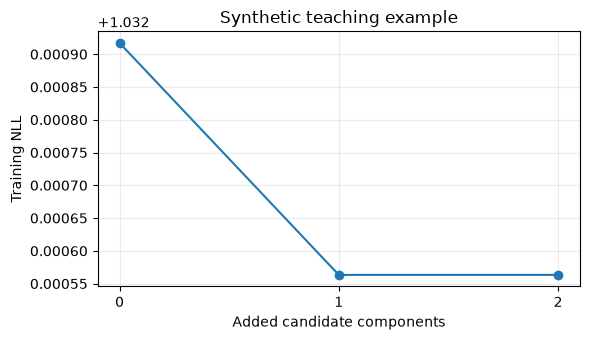

In [7]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(range(len(train_nll_history)), train_nll_history, marker="o")
ax.set(xlabel="Added candidate components", ylabel="Training NLL",
       title="Synthetic teaching example")
ax.set_xticks(range(len(train_nll_history)))
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 7. Inspect learned rules

The table below translates the strongest rule coefficients back to named
predicates for each component. Positive coefficients increase relative utility
within a component; their interpretation depends on the other rules and the
available alternatives. They are not causal effects.

In [8]:
rule_rows = []
for component, (weight, preference, rules) in enumerate(zip(
        model.proportion, model.taste_list, model.rule_set_list)):
    coefficients = preference.linear.weight.detach().numpy().ravel()
    for j in np.argsort(-np.abs(coefficients))[:5]:
        rule_rows.append({
            "component": component, "mixture_weight": weight,
            "rule": " AND ".join(encoder.feature_names_[k] for k in sorted(rules[j])),
            "coefficient": float(coefficients[j]),
        })
pd.DataFrame(rule_rows)

,component,mixture_weight,rule,coefficient
0,0,0.961911,"prop_log_historical_price in [-inf, 4.45172)",0.457145
1,0,0.961911,"price_usd in [-inf, 85.7739)",0.418565
2,0,0.961911,"prop_log_historical_price in [5.56401, 5.6724)",-0.405959
3,0,0.961911,"prop_starrating in (3, 4]",0.388646
4,0,0.961911,"prop_starrating in (4, 5]",0.387089
5,1,0.038089,"prop_starrating in (0, 1]",-5.788583
6,1,0.038089,"position in (2, 3] AND srch_length_of_stay in ...",4.301534
7,1,0.038089,"position in (2, 3] AND srch_children_count in ...",3.972059
8,1,0.038089,"price_usd in [320.781, inf)",-3.644014
9,1,0.038089,"prop_log_historical_price in [5.77076, inf)",-3.081127


## Next experiments

- Change the candidate-component count or the rule-length limit and examine both
  held-out NLL and rule complexity. Keep the test data out of tuning decisions;
  use a separate validation split for selecting hyperparameters.
- Inspect the predicate definitions in `data_utils.py` and compare them with the
  data you want to model.
- Use your processed Expedia CSVs following `data/README.md`.

This release does not reproduce every dataset, baseline, hyperparameter sweep,
or table in the paper. See the README for the changes from the original teaching
notebook and the scope of the runnable example.